# Reading Gmsh meshes with `pyramids-mesh`

**Gmsh** is the widely used open-source finite-element mesh generator; its `.msh` format is a common interchange for unstructured meshes feeding FE/FV solvers. Unlike the global climate grids in this series, a Gmsh mesh is a **planar engineering mesh** — raw `(x, y)` coordinates in model units, with **no georeferencing**. The `gmsh` driver supports both the legacy v2.2 ASCII and the v4.1 formats.

This notebook reads `insulated-2.2.msh` — a genuine Gmsh mesh of **111 triangles** over **67 nodes** — into a pyramids `UgridDataset` and tours the operations it supports. Being triangular, it supports circumcenters.

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 3. Locate the example file

This notebook lives in `docs/examples/`, so `examples/data/` is two levels up. The Gmsh sample is `gmsh/insulated-2.2.msh`, a 111-triangle mesh (Gmsh 2.2 ASCII) from the meshio test suite.

Paths inside a notebook are always written **relative to the notebook itself**, and pyramids' `read_file` accepts a `pathlib.Path` directly — we pass the `Path`, never `str(path)`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "gmsh" / "insulated-2.2.msh"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/gmsh/insulated-2.2.msh'), True)

## 4. Read the mesh

`UgridDataset.read_file(path, driver="gmsh")` dispatches the file to the `gmsh` driver, which parses it and hands back a `UgridDataset` — the same pyramids type produced from a native UGRID NetCDF file. We name the driver explicitly here because several formats share the `.msh` suffix; `read_file` can auto-detect, but being explicit is unambiguous.

In [3]:
ds = UgridDataset.read_file(mesh_file, driver="gmsh")
type(ds).__name__

'UgridDataset'

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

From here nothing in the API remembers the data came from a Gmsh mesh — it is a first-class pyramids object.

## 5. Explore the dataset

A `UgridDataset` exposes summary properties describing the whole mesh: `n_node` / `n_face` (size), `crs` / `epsg` (georeferencing, if the format recorded any), `bounds` (spatial extent), and `data_variable_names` (any attached fields).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": ds.bounds,
    "data_variable_names": ds.data_variable_names,
})

n_node                                                                67
n_face                                                               111
crs                                                                 None
epsg                                                                None
bounds                 (-2.96649247971263, -2.991611391173865, 3.0, 2...
data_variable_names                                                   []
dtype: object

**111 triangular faces** on **67 nodes**. `crs`/`epsg` are `None` — Gmsh stores raw model coordinates with no CRS — and `data_variable_names` is empty: a mesh-generator file carries geometry only, no solver fields. The `bounds` are in the model's own (unitless) coordinates.

## 6. Coordinates are planar model units

Gmsh coordinates are **not** geographic — they are raw `(x, y)` in whatever units the `.geo` model used (here roughly ±3). There is no radian-vs-degree question: the values are small planar numbers centred near the origin, and no CRS is attached.

In [6]:
nx, ny = ds.mesh.node_x, ds.mesh.node_y
pd.Series({
    "node_x min/max": (float(nx.min()), float(nx.max())),
    "node_y min/max": (float(ny.min()), float(ny.max())),
    "two_pi": float(2*np.pi), "half_pi": float(np.pi/2),
})

node_x min/max                   (-2.96649247971263, 3.0)
node_y min/max    (-2.991611391173865, 2.991611391889027)
two_pi                                           6.283185
half_pi                                          1.570796
dtype: object

`node_x`/`node_y` sit in a small range around the origin (≈ ±3) — engineering model coordinates, neither radians (→ 2π) nor degrees (→ ±180). You would assign a CRS only if you knew the model's real-world placement.

## 7. The underlying `Mesh2d` topology

`ds.mesh` is the `Mesh2d` holding the raw topology. The arrays you reach for most often are `node_x`/`node_y` (node coordinates), `face_node_connectivity.data` — the `(n_face, k)` table listing the node indices of each face — and `face_areas` (one value per face).

In [7]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
{
    "n_node": int(mesh.node_x.shape[0]),
    "connectivity_shape": conn.shape,
    "face_areas_shape": mesh.face_areas.shape,
    "face_centroids_shape": np.asarray(mesh.face_centroids).shape,
}

{'n_node': 67,
 'connectivity_shape': (111, 3),
 'face_areas_shape': (111,),
 'face_centroids_shape': (2, 111)}

The connectivity shape is **`(111, 3)`**: exactly **three** nodes per face — a triangular mesh, which makes circumcenters well-defined. `face_centroids` is returned as `(2, n_face)`.

## 8. The wireframe

The simplest visualization needs no data — just draw the cell edges. `plot_outline()` renders the mesh skeleton through cleopatra; it is the fastest sanity check that a file read in correctly.

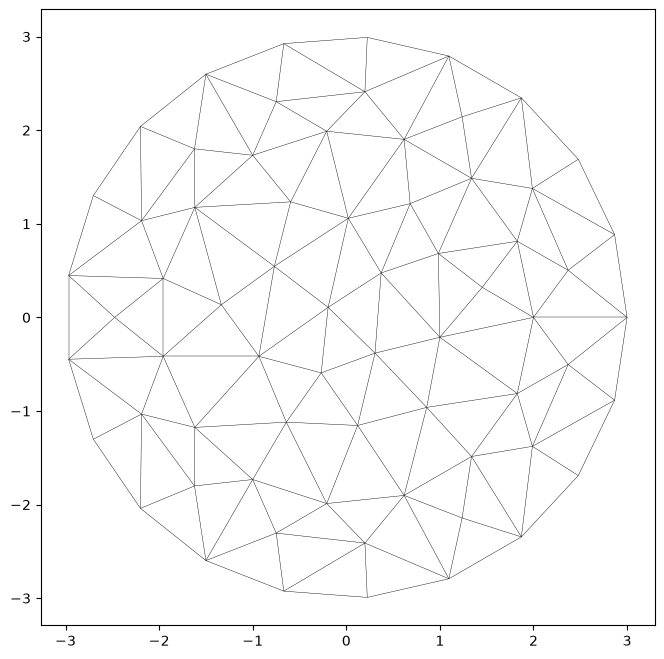

In [8]:
ds.plot_outline()


The wireframe is the mesh *as the solver sees it* — an unstructured grid of triangles, finer where the geometry demands resolution. Seeing it is the fastest confirmation the file read in correctly.

## 9. A data map: per-cell area

This mesh carries no field values, so we synthesise one. We compute each cell's area from the geometry and attach it as a face-located variable with `with_variable(...)`, which returns a **new** dataset (the original `ds` is left untouched). Colouring by it produces the generic pyramids data-map that any per-cell field (depth, velocity, …) would use.

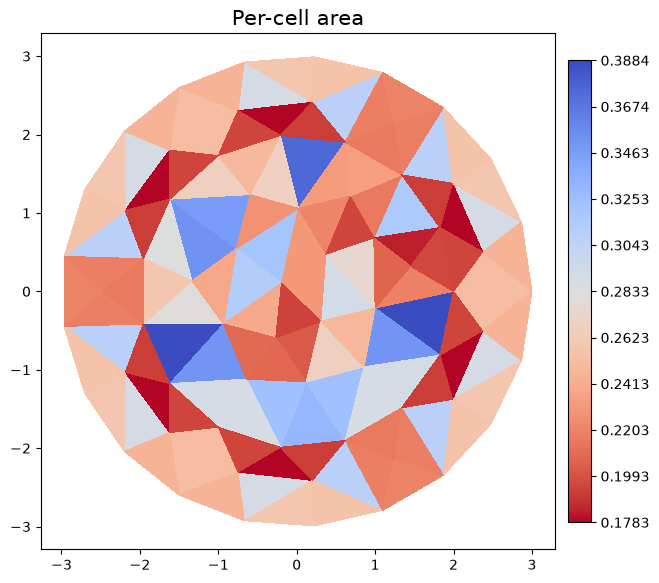

In [9]:
d2 = ds.with_variable("face_area", mesh.face_areas, location="face")
d2.plot("face_area", cmap="viridis", colorbar=True, title="Per-cell area")


Each triangle is shaded by its area: darker cells are smaller (the refined regions), brighter cells larger (the coarse interior). This is the generic pyramids data-map path — any per-cell field would plot identically.

`summary()` reports per-variable statistics (count, min, max, mean, std) for every attached field.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
face_area,111,0.178301,0.38836,0.25094,0.049831


The single `face_area` row gives the triangle count and the min/max cell sizes — a numeric companion to the colour map, confirming the refinement gradient.

## 10. GIS operations, for free

Because the mesh is a pyramids object, the pyramids GIS layer applies directly — none of these methods live in `pyramids-mesh`. We tour a few.

### Faces as a `GeoDataFrame`

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or for spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((-0.19413 0.10715, 0.02141 1.05898, -..."
1,"POLYGON ((-0.93395 -0.41582, -0.19413 0.10715,..."
2,"POLYGON ((0.02141 1.05898, -0.19413 0.10715, 0..."
3,"POLYGON ((-1.9563 -0.41582, -1.61803 -1.17557,..."
4,"POLYGON ((0.61803 1.90211, -0.20906 1.98904, 0..."


One row per face, each carrying its cell polygon. Plotting the `GeoDataFrame` directly with geopandas draws every face as a filled polygon — a second, vector-native view of the same mesh.

<Axes: xlabel='x', ylabel='y'>

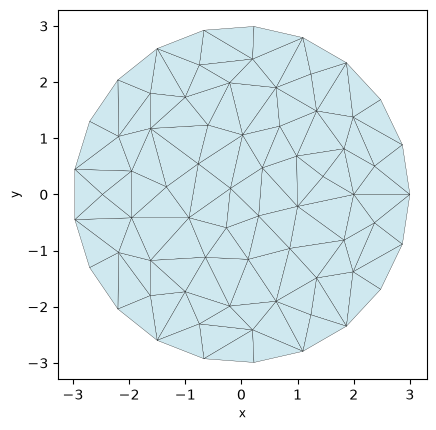

In [12]:
gdf.plot(edgecolor="black", linewidth=0.2, facecolor="#cfe8ef")


One triangle polygon per row. The CRS is unset (inherited the mesh's `None`); you would assign one before exporting to a shapefile.

### Bounding polygon

`bounding_polygon()` dissolves the triangles into the mesh's outer boundary — a shapely `Polygon`. Because this is a small planar mesh with no periodic seam, it dissolves cleanly.

In [13]:
poly = ds.bounding_polygon()
{"type": type(poly).__name__, "bounds": ds.bounds}

{'type': 'Polygon',
 'bounds': (-2.96649247971263, -2.991611391173865, 3.0, 2.991611391889027)}

A single `Polygon` outlining the meshed domain — an ordinary shapely geometry, the gateway to the shapely/geopandas ecosystem for clipping and spatial joins.

### Circumcenters

`circumcenters()` returns an `(n_face, 2)` array of per-cell circumcenter coordinates — the points a finite-volume scheme places unknowns at. It is **defined only for triangular meshes**, and the Gmsh mesh is triangular, so it works here.

In [14]:
cc = ds.circumcenters()
cc.shape, cc[:3]

((111, 2),
 array([[-0.25617308,  0.62151923],
        [-0.70061175,  0.03886316],
        [-0.10250116,  0.58672018]]))

`(n_face, 2)` — one `(x, y)` circumcenter per triangle. That these derived quantities are a single method call away is the whole point of turning the file into a pyramids object.

### Boundary edges and face adjacency

`exterior_edges()` returns the indices of the edges that lie on the mesh boundary (each interior edge is shared by two faces; a boundary edge by one). `sparse_adjacency()` returns the face–face adjacency as a SciPy sparse matrix — the graph a flow solver walks.

In [15]:
ee = ds.exterior_edges()
adj = ds.sparse_adjacency()
{
    "n_boundary_edges": int(ee.shape[0]),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}

{'n_boundary_edges': 21, 'adjacency_shape': (111, 111), 'adjacency_nnz': 312}

The boundary-edge count is the triangles' outer rim; the `(111, 111)` adjacency matrix (two non-zeros per shared edge) is the neighbour graph a finite-volume scheme walks.

### Connected components

`connected_components()` labels each face by which connected piece of the adjacency graph it belongs to. The number of distinct labels tells you whether the mesh is one contiguous surface or several disjoint pieces.

In [16]:
labels = ds.connected_components()
n_comp = int(np.unique(labels).size)
{"n_components": n_comp, "counts": np.bincount(labels).tolist()}

{'n_components': 1, 'counts': [111]}

**One** component: every triangle is reachable from every other, so the meshed domain is a single connected region.

### Cropping to a bounding box

`crop(bbox=(xmin, ymin, xmax, ymax))` returns a new `UgridDataset` holding only the faces inside the box — the mesh equivalent of a spatial window. (`subset_by_bounds(xmin, ymin, xmax, ymax)` does the same with positional arguments.) We crop to one quadrant of the extent and plot the result.

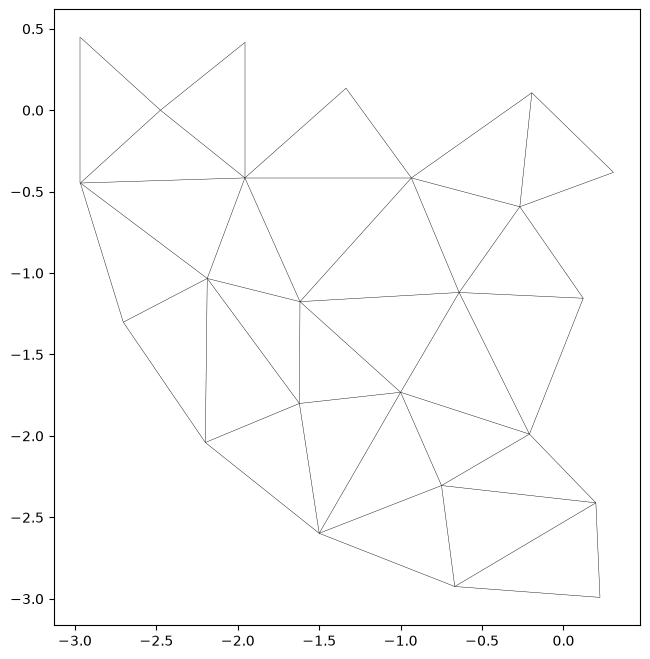

In [17]:
b = ds.bounds
bbox = (b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2)
cropped = ds.crop(bbox=bbox)
cropped.plot_outline()


Cropping to one quadrant of the extent keeps only the triangles whose centroids fall in the box — a contiguous corner of the original mesh.

### Writing the mesh back out

`to_file(path, driver=...)` serialises the mesh through any **write-capable** driver. We round-trip to Stanford **PLY** (`driver="ply"`), which stores arbitrary polygon faces, into a temp file and read it back to confirm the topology survived.

In [18]:
import tempfile
out = Path(tempfile.gettempdir()) / "gmsh_roundtrip.ply"
ds.to_file(out, driver="ply")
back = UgridDataset.read_file(out, driver="ply")
{"wrote_bytes": out.stat().st_size, "n_face_back": back.n_face, "matches": back.n_face == ds.n_face}

{'wrote_bytes': 4234, 'n_face_back': 111, 'matches': True}

The face count survives the round-trip: the mesh we read from a Gmsh mesh wrote cleanly to a different format and came back identical. PLY is used because this format's own driver is read-only — `to_file` dispatches to whichever driver advertises a write capability.

### Back to `xarray`

`to_xarray()` exposes the dataset as an `xarray.Dataset` of UGRID variables — the bridge to the wider scientific-Python stack (dask, NetCDF export, CF tooling).

In [19]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.dims)

('Dataset',
 ['mesh2d_scalar', 'mesh2d_nNodes', 'mesh2d_nFaces', 'mesh2d_nMaxFaceNodes'])

A standard `xarray.Dataset`: from here the mesh can be written to NetCDF, chunked with dask, or fed to any CF-aware tool.

## 11. What we *cannot* do here, and why

Two pyramids operations are unavailable on this mesh:

- **`to_crs(epsg)` — skipped.** The Gmsh mesh has **no CRS** (`crs` is `None`), so pyramids refuses to reproject: `to_crs` raises *"Cannot reproject: source CRS is unknown."* Gmsh coordinates are planar model units; you would assign the real-world CRS (if the model's georeferencing is known) before reprojecting.
- **`rasterize_like(...)` / `regrid(...)` — out of scope here.** These are genuine pyramids capabilities but need a target raster/mesh and a resampling choice to be meaningful — a topic for a dedicated tutorial, not this format tour.

## Takeaway

- The `gmsh` driver reads a `.msh` finite-element mesh (v2.2 or v4.1) into a pyramids `UgridDataset`.
- Gmsh cells are **triangles** (`k = 3`) with **planar, non-georeferenced** coordinates (no CRS, no radian/degree question); being triangular, **`circumcenters()` works**.
- The file is geometry-only; we attached a geometric `face_area` for a data map.
- The pyramids GIS layer applies in full — `to_geodataframe`, `bounding_polygon`, circumcenters, adjacency, components, crop, PLY round-trip, `to_xarray` — while `to_crs` is skipped because no CRS is recorded.